## 1. Setup, configuration and environment capture

In [ ]:
%pip install -q python-docx scikit-learn pandas matplotlib

In [ ]:
import os, sys, json, time, math, gc, random, subprocess, datetime, platform, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# ------------------------------------------------------------------ configuration (edit here only)
SMOKE_TEST   = False     # True: ~20 imgs/class, 1 epoch, results go to *_smoke files. Use only to check the pipeline.
FORCE_RERUN  = False     # False: a finished run found in outputs/results.json is skipped (resume after a Colab disconnect)
SEED         = 42        # global seed / data-split seed
SEEDS_ABLATION = [42, 123]   # A0-A3 (plain & residual) are repeated with both seeds; remove 123 if quota is short
IMG_BENCH, IMG_ABL, IMG_A4 = 96, 64, 96      # architecture benchmark / ablation / transfer-branch resolution
N_TRAIN_PER_CLASS, N_VAL_PER_CLASS = (20, 10) if SMOKE_TEST else (1200, 300)   # -> 12 000 train / 3 000 val
EPOCHS_ARCH  = 1 if SMOKE_TEST else 5        # common 5-epoch maximum for the four scratch architectures (assignment rule)
EPOCHS_ABL   = 1 if SMOKE_TEST else 10       # A0-A3 (not fixed by the assignment; identical for all ablation variants)
EPOCHS_A4F   = 1 if SMOKE_TEST else 5        # frozen-trunk feature extraction
EPOCHS_A4T   = 1 if SMOKE_TEST else 5        # fine-tuning, starts from the A4-F best checkpoint
BATCH_CANDIDATES = [32, 16]                  # tried in this order; OOM at 32 -> retry at 16 (attempts are logged)
LR_CANDIDATES = [1e-4, 3e-4, 1e-3]           # only used by the LR sanity check
COMMON_LR    = 3e-4                          # Adam benchmark LR (may be lowered by the sanity check if 3e-4 diverges)
LR_FINETUNE  = 1e-5                          # A4-T
A4_WEIGHTS   = "imagenet"                    # ResNet50 weights for A4 only
WINNER_POOL  = None                          # None = every successful run is eligible for the final test; or a list of run_ids

OUT = Path("outputs_smoke" if SMOKE_TEST else "outputs")
FIG, CKPT, HIST, LOGS = OUT / "figures", OUT / "checkpoints", OUT / "histories", OUT / "logs"
for d in (OUT, FIG, CKPT, HIST, LOGS, Path("src")):   # src/ is needed by the %%writefile cells
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV  = Path("results_smoke.csv" if SMOKE_TEST else "results.csv")
RESULTS_JSON = OUT / "results.json"

# ------------------------------------------------------------------ GPU, mixed precision, seeds
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
USE_MIXED = bool(gpus)
if USE_MIXED:
    keras.mixed_precision.set_global_policy("mixed_float16")   # logits layer is float32 (see src/models.py)
print("GPUs:", gpus, "| mixed_float16:", USE_MIXED)

def set_all_seeds(seed):
    keras.utils.set_random_seed(seed)      # python + numpy + TensorFlow seeds

set_all_seeds(SEED)

def git_hash():
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        return "not a git checkout - run `git rev-parse HEAD` in your repo and paste it into README.md"

def smi():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
    except Exception:
        return "nvidia-smi not available (no GPU runtime)"

ENV = {
    "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "python": platform.python_version(), "platform": platform.platform(),
    "tensorflow": tf.__version__, "keras": keras.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "gpu_devices": [str(g) for g in gpus], "mixed_precision": USE_MIXED,
    "seed": SEED, "ablation_seeds": SEEDS_ABLATION, "git_commit": git_hash(),
    "config": {k: v for k, v in dict(IMG_BENCH=IMG_BENCH, IMG_ABL=IMG_ABL, IMG_A4=IMG_A4, EPOCHS_ARCH=EPOCHS_ARCH,
               EPOCHS_ABL=EPOCHS_ABL, EPOCHS_A4F=EPOCHS_A4F, EPOCHS_A4T=EPOCHS_A4T, BATCH_CANDIDATES=BATCH_CANDIDATES,
               COMMON_LR=COMMON_LR, LR_FINETUNE=LR_FINETUNE, SMOKE_TEST=SMOKE_TEST).items()},
}
json.dump(ENV, open(OUT / "environment.json", "w"), indent=2)
(LOGS / "nvidia_smi.txt").write_text(smi())
print(json.dumps(ENV, indent=2)); print(smi())

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | mixed_float16: True
{
  "date_utc": "2026-11-21T07:20:39+00:00",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "gpu_devices": [
    "PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"
  ],
  "mixed_precision": true,
  "seed": 42,
  "ablation_seeds": [
    42,
    123
  ],
  "git_commit": "not a git checkout - run `git rev-parse HEAD` in your repo and paste it into README.md",
  "config": {
    "IMG_BENCH": 96,
    "IMG_ABL": 64,
    "IMG_A4": 96,
    "EPOCHS_ARCH": 5,
    "EPOCHS_ABL": 10,
    "EPOCHS_A4F": 5,
    "EPOCHS_A4T": 5,
    "BATCH_CANDIDATES": [
      32,
      16
    ],
    "COMMON_LR": 0.0003,
    "LR_FINETUNE": 1e-05,
    "SMOKE_TEST": false
  }
}
Sat Nov 21 07:20:40 2026       
+--------------------------------------------------------------------------------------

## 2. Part I – Numerical reasoning (20 marks)
Each answer is derived by formula first, then **verified by building the same layers in Keras**. The written derivations are in Appendix A of the report.

In [ ]:
# ---------------------------------------------------------------- Q1: shape / parameter trace (5 marks)
# Formulas:  padding="same": out = ceil(in / stride) ;  padding="valid": out = floor((in - k)/stride) + 1
#            Conv params = k*k*C_in*C_out + C_out(bias) ;  Dense params = in*out + out ;  MACs(conv) = H_out*W_out*C_out*(k*k*C_in)
def same_out(n, s):      return math.ceil(n / s)
def valid_out(n, k, s):  return (n - k) // s + 1

h_conv1 = same_out(96, 2)                    # Conv2D(32, k5, s2, same)  -> 48
h_pool  = valid_out(h_conv1, 2, 2)           # MaxPool2D(2, s2)          -> 24
h_conv2 = same_out(h_pool, 1)                # Conv2D(64, k3, s1, same)  -> 24
q1 = {
    "shapes": {"input": (96, 96, 3), "conv1": (h_conv1, h_conv1, 32), "pool": (h_pool, h_pool, 32),
               "conv2": (h_conv2, h_conv2, 64), "gap": (64,), "dense": (10,)},
    "params": {"conv1": 5*5*3*32 + 32, "conv2": 3*3*32*64 + 64, "dense": 64*10 + 10},
    "macs_conv1": h_conv1 * h_conv1 * 32 * (5*5*3),
}
q1["params"]["total"] = sum(q1["params"].values())

q1_model = keras.Sequential([
    keras.Input((96, 96, 3)),
    layers.Conv2D(32, 5, strides=2, padding="same", use_bias=True, name="conv1"),
    layers.MaxPool2D(2, strides=2, name="pool"),
    layers.Conv2D(64, 3, strides=1, padding="same", use_bias=True, name="conv2"),
    layers.GlobalAveragePooling2D(name="gap"),
    layers.Dense(10, use_bias=True, name="dense")], name="Q1_trace")
q1_model.summary()
for l in q1_model.layers:
    assert tuple(l.output.shape[1:]) == q1["shapes"][l.name], l.name
for n in ("conv1", "conv2", "dense"):
    assert q1_model.get_layer(n).count_params() == q1["params"][n], n
assert q1_model.count_params() == q1["params"]["total"]
print("Q1 verified:", q1)

# ---------------------------------------------------------------- Q2: one 7x7 vs three 3x3 (5 marks)
C = 64
rf_7x7, rf_3x3_stack = 7, 1 + 3 * (3 - 1)         # RF of a stack of n stride-1 kxk convs = 1 + n*(k-1)
w_7x7, w_3x3_stack = 7*7*C*C, 3 * (3*3*C*C)
q2 = {"rf_7x7": rf_7x7, "rf_3x3x3": rf_3x3_stack, "weights_7x7": w_7x7, "weights_3x3x3": w_3x3_stack,
      "weight_ratio": w_3x3_stack / w_7x7, "saving_pct": 100 * (1 - w_3x3_stack / w_7x7),
      "relu_layers": {"7x7": 1, "3x3x3": 3}}
a = keras.Sequential([keras.Input((32, 32, C)), layers.Conv2D(C, 7, padding="same", use_bias=False)])
b = keras.Sequential([keras.Input((32, 32, C))] + [layers.Conv2D(C, 3, padding="same", use_bias=False) for _ in range(3)])
assert a.count_params() == w_7x7 and b.count_params() == w_3x3_stack
print("Q2 verified:", q2)

# ---------------------------------------------------------------- Q3: Inception arithmetic (5 marks)
def inception_weights(cin, c1, c3r, c3, c5r, c5, pp, reductions=True):
    w = {"branch1 1x1": cin * c1,
         "branch4 pool-proj 1x1": cin * pp}
    if reductions:
        w["branch2 1x1 red + 3x3"] = cin * c3r + 3*3*c3r*c3
        w["branch3 1x1 red + 5x5"] = cin * c5r + 5*5*c5r*c5
    else:
        w["branch2 3x3 direct"] = 3*3*cin*c3
        w["branch3 5x5 direct"] = 5*5*cin*c5
    w["total"] = sum(w.values())
    return w

cfg3 = dict(cin=192, c1=64, c3r=32, c3=128, c5r=16, c5=32, pp=32)
q3_with, q3_without = inception_weights(**cfg3), inception_weights(**cfg3, reductions=False)
q3 = {"branch_shapes": {"1": (28, 28, 64), "2": (28, 28, 128), "3": (28, 28, 32), "4": (28, 28, 32)},
      "concat_shape": (28, 28, 64 + 128 + 32 + 32), "weights_with_reductions": q3_with,
      "weights_without_reductions": q3_without, "ratio": q3_without["total"] / q3_with["total"]}

def inception_keras(reductions=True):
    i = keras.Input((28, 28, 192))
    cv = lambda x, f, k: layers.Conv2D(f, k, padding="same", use_bias=False)(x)
    b1 = cv(i, 64, 1)
    b2 = cv(cv(i, 32, 1), 128, 3) if reductions else cv(i, 128, 3)
    b3 = cv(cv(i, 16, 1), 32, 5) if reductions else cv(i, 32, 5)
    b4 = cv(layers.MaxPool2D(3, strides=1, padding="same")(i), 32, 1)
    return keras.Model(i, layers.Concatenate()([b1, b2, b3, b4]))
mw, mo = inception_keras(True), inception_keras(False)
assert mw.output_shape[1:] == q3["concat_shape"] and mw.count_params() == q3_with["total"] == 77312
assert mo.count_params() == q3_without["total"] == 393216
print("Q3 verified:", json.dumps(q3, indent=1, default=str))

# ---------------------------------------------------------------- Q4: projection shortcut and BatchNorm (5 marks)
# x: 32x32x64, F(x): 16x16x128  ->  shortcut must be 1x1 conv, stride 2, 128 filters, no bias  (weights = 1*1*64*128)
proj = keras.Sequential([keras.Input((32, 32, 64)), layers.Conv2D(128, 1, strides=2, use_bias=False)])
assert proj.output_shape[1:] == (16, 16, 128) and proj.count_params() == 64 * 128 == 8192
# BatchNorm: training -> per-channel mean/var over (N,H,W) of the mini-batch; inference -> moving averages
bn = layers.BatchNormalization(momentum=0.9, epsilon=1e-3, dtype="float32")   # float32: the global mixed_float16 policy would add fp16 rounding error
xb = np.random.RandomState(0).randn(8, 4, 4, 3).astype("float32") * 3 + 5
y_train = bn(xb, training=True).numpy()
mu, var = xb.mean(axis=(0, 1, 2)), xb.var(axis=(0, 1, 2))
assert np.allclose(y_train, (xb - mu) / np.sqrt(var + 1e-3), atol=1e-3)           # batch statistics used in training
assert np.allclose(bn.moving_mean.numpy(), 0.9 * 0 + 0.1 * mu, atol=1e-3)         # moving mean update: m*old + (1-m)*batch
y_inf = bn(xb, training=False).numpy()
mm, mv = bn.moving_mean.numpy(), bn.moving_variance.numpy()
assert np.allclose(y_inf, (xb - mm) / np.sqrt(mv + 1e-3), atol=1e-3)               # inference uses the moving statistics
q4 = {"projection": "Conv2D(128, kernel 1x1, stride 2, padding same, use_bias=False)", "projection_weights": 8192,
      "output": "y = ReLU(F(x) + W_s * x)", "bn_axis": "channel axis (-1); statistics over N,H,W"}
print("Q4 verified:", q4)
json.dump({"q1": q1, "q2": q2, "q3": q3, "q4": q4}, open(OUT / "part1_numerical_checks.json", "w"), indent=2, default=str)

Model: "Q1_trace"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 48, 48, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,578 (84.29 KB)

 Trainable params: 21,578 (84.29 KB)

 Non-trainable params: 0 (0.00 B)

Q1 verified: {'shapes': {'input': (96, 96, 3), 'conv1': (48, 48, 32), 'pool': (24, 24, 32), 'conv2': (24, 24, 64), 'gap': (64,), 'dense': (10,)}, 'params': {'conv1': 2432, 'conv2': 18496, 'dense': 650, 'total': 21578}, 'macs_conv1': 5529600}
Q2 verified: {'rf_7x7': 7, 'rf_3x3x3': 7, 'weights_7x7': 200704, 'weights_3x3x3': 110592, 'weight_ratio': 0.5510204081632653, 'saving_pct': 44.89795918367348, 'relu_layers': {'7x7': 1, '3x3x3': 3}}
Q3 verified: {
 "branch_shapes": {
  "1": [
   28,
   28,
   64
  ],
  "2": [
   28,
   28,
   128
  ],
  "3": [
   28,
   28,
   32
  ],
  "4": [
   28,
   28,
   32
  ]
 },
 "concat_shape": [
  28,
  28,
  256
 ],
 "weights_with_reductions": {
  "branch1 1x1": 12288,
  "branch4 pool-proj 1x1": 6144,
  "branch2 1x1 red + 3x3": 43008,
  "branch3 1x1 red + 5x5": 15872,
  "total": 77312
 },
 "weights_without_reductions": {
  "branch1 1x1": 12288,
  "branch4 pool-proj 1x1": 6144,
  "branch2 3x3 direct": 221184,
  "branch3 5x5 direct": 153600,
  "total": 393

## 3. Data protocol (CIFAR-10 only)
* Source: `keras.datasets.cifar10` – **original 50 000-image training partition only** for training and validation.
* One fixed, stratified **12 000-image training subset** (1 200 / class) and a **disjoint 3 000-image validation subset** (300 / class), seed 42; indices are saved.
* The original **10 000-image test split is locked**: it is only read inside `evaluate_on_test_once()` after the winner has been written to disk.
* Images are resized **inside the `tf.data` pipeline** (bilinear, on demand – no enlarged copy is stored). Up-scaling adds no new detail.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 876s 5us/step
train (12000, 32, 32, 3) val (3000, 32, 32, 3) | test split locked: (10000, 32, 32, 3)


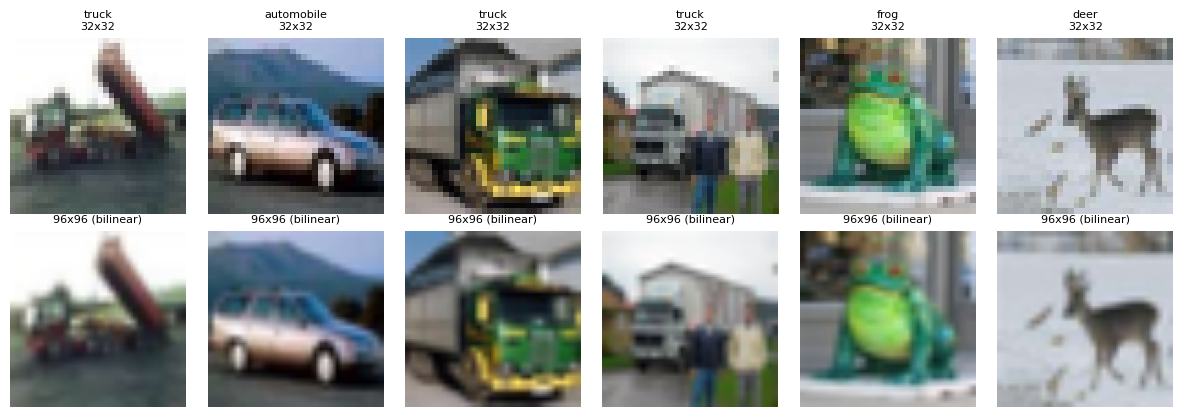

In [ ]:
(x_all, y_all), (_x_test_raw, _y_test_raw) = keras.datasets.cifar10.load_data()
y_all = y_all.ravel()
TEST_LOCKED = {"x": _x_test_raw, "y": _y_test_raw.ravel()}        # not touched until the final evaluation
del _x_test_raw, _y_test_raw
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

rng = np.random.RandomState(SEED)
train_idx, val_idx = [], []
for c in range(10):                                   # stratified: same number of images per class
    idx = np.where(y_all == c)[0]
    rng.shuffle(idx)
    train_idx += idx[:N_TRAIN_PER_CLASS].tolist()
    val_idx   += idx[N_TRAIN_PER_CLASS:N_TRAIN_PER_CLASS + N_VAL_PER_CLASS].tolist()
train_idx, val_idx = np.array(sorted(train_idx)), np.array(sorted(val_idx))
assert len(set(train_idx) & set(val_idx)) == 0, "train/val must be disjoint"
assert len(train_idx) == 10 * N_TRAIN_PER_CLASS and len(val_idx) == 10 * N_VAL_PER_CLASS
x_tr, y_tr, x_va, y_va = x_all[train_idx], y_all[train_idx], x_all[val_idx], y_all[val_idx]
assert (np.bincount(y_tr) == N_TRAIN_PER_CLASS).all() and (np.bincount(y_va) == N_VAL_PER_CLASS).all()
json.dump({"seed": SEED, "train_idx": train_idx.tolist(), "val_idx": val_idx.tolist(),
           "note": "indices into the ORIGINAL CIFAR-10 training partition (50 000 images)"},
          open(OUT / "data_indices.json", "w"))
print("train", x_tr.shape, "val", x_va.shape, "| test split locked:", TEST_LOCKED["x"].shape)

def make_dataset(x, y, size, batch, training, seed=SEED):
    # uint8 32x32 -> float32 [0,255] -> bilinear resize to (size,size) inside tf.data; scaling to [0,1] happens inside the model
    ds = tf.data.Dataset.from_tensor_slices((x, y.astype("int32")))
    if training:
        ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
    def prep(img, label):
        img = tf.image.resize(tf.cast(img, tf.float32), (size, size), method="bilinear")
        return img, label
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).batch(batch).prefetch(tf.data.AUTOTUNE)

# visual reminder that up-scaling adds no information
fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
for j in range(6):
    img = x_tr[j]
    ax[0, j].imshow(img); ax[0, j].set_title(f"{CLASS_NAMES[y_tr[j]]}\n32x32", fontsize=8); ax[0, j].axis("off")
    ax[1, j].imshow(tf.image.resize(img.astype("float32"), (96, 96)).numpy().astype("uint8")); ax[1, j].set_title("96x96 (bilinear)", fontsize=8); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(FIG / "data_samples.png", dpi=120); plt.show()

## 4. Part II – the four architectures (implemented manually in `src/models.py`)
The next cell writes the model file (so the notebook is self-contained and the repo gets the optional `src/models.py`).

In [ ]:
%%writefile src/models.py
"""
models.py -- model definitions for Deep Learning Assignment 02 (TensorFlow / Keras only).

Contents
  * build_alexnet, build_vgg16, build_googlenet, build_resnet18   (Part II, written manually)
  * build_ablation / build_a0 ... build_a3                         (Part III, A0-A3)
  * build_a4, unfreeze_resnet50_top                                (Part III, A4-F / A4-T transfer branch)
  * count_params, stage_shapes                                     (helpers)

Conventions shared by all scratch models
  * Input is a float32 image in the ORIGINAL [0, 255] scale; scratch models rescale by 1/255 inside the model
    (so the tf.data pipeline can feed ResNet50 the un-scaled images that resnet50.preprocess_input expects).
  * The last layer is Dense(10) with dtype float32 and NO softmax (logits), to be used with
    SparseCategoricalCrossentropy(from_logits=True) and mixed_float16.
  * ReLU layers use He-normal initialisation (see the deviation table in the report).
"""
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = 10
HE = "he_normal"


# --------------------------------------------------------------------------------------------------
# helpers
# --------------------------------------------------------------------------------------------------
def count_params(model):
    """Return (trainable, total) parameter counts. 'total' includes BatchNorm moving statistics."""
    trainable = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total


def stage_shapes(model, keywords):
    """List (layer name, output shape) for every layer whose name contains one of `keywords`."""
    rows = []
    for l in model.layers:
        if any(k in l.name for k in keywords):
            shp = l.output.shape if hasattr(l, "output") else None
            rows.append((l.name, tuple(shp)))
    return rows


def _logits(x, num_classes=NUM_CLASSES):
    # float32 logits head (required with mixed_float16)
    return layers.Dense(num_classes, dtype="float32", kernel_initializer=HE, name="logits")(x)


def augmentation_block(name="augment"):
    """Label-preserving augmentation: horizontal flip, <=10 % translation, small contrast jitter.
    Applied on the [0,255] image; the layers are active only when training=True."""
    return keras.Sequential(
        [layers.RandomFlip("horizontal"),
         layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
         layers.RandomContrast(0.1)],
        name=name)


# --------------------------------------------------------------------------------------------------
# Part II -- AlexNet
# --------------------------------------------------------------------------------------------------
def build_alexnet(input_shape=(96, 96, 3), num_classes=NUM_CLASSES):
    """AlexNet (Krizhevsky et al., 2012) adapted to 96x96 inputs / 10 classes.
    5 conv stages (96,256,384,384,256; 11x11/4, 5x5, 3x3 x3), overlapping 3x3/2 max-pool after conv1, conv2, conv5,
    two 4096-unit FC layers with dropout 0.5.  LRN and the two-GPU grouped convolutions are OMITTED (see report)."""
    inp = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    x = layers.Conv2D(96, 11, strides=4, padding="same", activation="relu", kernel_initializer=HE, name="conv1")(x)
    x = layers.MaxPool2D(3, strides=2, name="pool1")(x)
    x = layers.Conv2D(256, 5, padding="same", activation="relu", kernel_initializer=HE, name="conv2")(x)
    x = layers.MaxPool2D(3, strides=2, name="pool2")(x)
    x = layers.Conv2D(384, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv3")(x)
    x = layers.Conv2D(384, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv4")(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv5")(x)
    x = layers.MaxPool2D(3, strides=2, name="pool5")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc6")(x)
    x = layers.Dropout(0.5, name="drop6")(x)
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc7")(x)
    x = layers.Dropout(0.5, name="drop7")(x)
    out = _logits(x, num_classes)
    return keras.Model(inp, out, name="AlexNet")


# --------------------------------------------------------------------------------------------------
# Part II -- VGG16
# --------------------------------------------------------------------------------------------------
VGG16_CFG = [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)]   # (conv layers, filters) per block


def build_vgg16(input_shape=(96, 96, 3), num_classes=NUM_CLASSES, head="fc"):
    """VGG16 (Simonyan & Zisserman, 2014): 13 conv (3x3, same, ReLU) + 5 max-pool + 3 dense.
    head='fc'  -> canonical Flatten-FC4096-FC4096-10 classifier (used for the benchmark run)
    head='gap' -> GlobalAveragePooling-Dense(10) alternative (analytical comparison only, never trained)."""
    inp = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    for b, (n, f) in enumerate(VGG16_CFG, start=1):
        for i in range(1, n + 1):
            x = layers.Conv2D(f, 3, padding="same", activation="relu", kernel_initializer=HE,
                              name=f"block{b}_conv{i}")(x)
        x = layers.MaxPool2D(2, strides=2, name=f"block{b}_pool")(x)
    if head == "fc":
        x = layers.Flatten(name="flatten")(x)
        x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc1")(x)
        x = layers.Dropout(0.5, name="drop1")(x)
        x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc2")(x)
        x = layers.Dropout(0.5, name="drop2")(x)
    else:
        x = layers.GlobalAveragePooling2D(name="gap")(x)
    out = _logits(x, num_classes)
    return keras.Model(inp, out, name="VGG16" if head == "fc" else "VGG16_GAPhead")


# --------------------------------------------------------------------------------------------------
# Part II -- GoogLeNet / Inception-v1
# --------------------------------------------------------------------------------------------------
# (1x1, 3x3-reduce, 3x3, 5x5-reduce, 5x5, pool-proj) -- Table 1 of Szegedy et al. (2015)
INCEPTION_CFG = {
    "3a": (64, 96, 128, 16, 32, 32),    "3b": (128, 128, 192, 32, 96, 64),
    "4a": (192, 96, 208, 16, 48, 64),   "4b": (160, 112, 224, 24, 64, 64),
    "4c": (128, 128, 256, 24, 64, 64),  "4d": (112, 144, 288, 32, 64, 64),
    "4e": (256, 160, 320, 32, 128, 128),
    "5a": (256, 160, 320, 32, 128, 128), "5b": (384, 192, 384, 48, 128, 128),
}


def _cr(x, f, k, name, s=1):
    return layers.Conv2D(f, k, strides=s, padding="same", activation="relu", kernel_initializer=HE, name=name)(x)


def inception_module(x, cfg, name):
    c1, c3r, c3, c5r, c5, pp = cfg
    b1 = _cr(x, c1, 1, f"{name}_1x1")
    b2 = _cr(_cr(x, c3r, 1, f"{name}_3x3_reduce"), c3, 3, f"{name}_3x3")
    b3 = _cr(_cr(x, c5r, 1, f"{name}_5x5_reduce"), c5, 5, f"{name}_5x5")
    b4 = layers.MaxPool2D(3, strides=1, padding="same", name=f"{name}_pool")(x)
    b4 = _cr(b4, pp, 1, f"{name}_pool_proj")
    shapes = {tuple(b.shape[1:3]) for b in (b1, b2, b3, b4)}
    assert len(shapes) == 1, f"{name}: branch spatial shapes differ {shapes}"          # unit check
    return layers.Concatenate(name=f"{name}_concat")([b1, b2, b3, b4])


def build_googlenet(input_shape=(96, 96, 3), num_classes=NUM_CLASSES):
    """GoogLeNet / Inception-v1: stem + 9 Inception modules (3a-3b, 4a-4e, 5a-5b) + GAP + dropout 0.4 + 10-way head.
    Auxiliary classifiers are NOT built/trained, and LRN is omitted (see report)."""
    inp = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    x = _cr(x, 64, 7, "stem_conv7x7", s=2)
    x = layers.MaxPool2D(3, strides=2, padding="same", name="stem_pool1")(x)
    x = _cr(x, 64, 1, "stem_conv1x1")
    x = _cr(x, 192, 3, "stem_conv3x3")
    x = layers.MaxPool2D(3, strides=2, padding="same", name="stem_pool2")(x)
    for m in ("3a", "3b"):
        x = inception_module(x, INCEPTION_CFG[m], f"inception_{m}")
    x = layers.MaxPool2D(3, strides=2, padding="same", name="pool3")(x)
    for m in ("4a", "4b", "4c", "4d", "4e"):
        x = inception_module(x, INCEPTION_CFG[m], f"inception_{m}")
    x = layers.MaxPool2D(3, strides=2, padding="same", name="pool4")(x)
    for m in ("5a", "5b"):
        x = inception_module(x, INCEPTION_CFG[m], f"inception_{m}")
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.4, name="drop")(x)
    out = _logits(x, num_classes)
    return keras.Model(inp, out, name="GoogLeNet")


# --------------------------------------------------------------------------------------------------
# Part II -- ResNet-18
# --------------------------------------------------------------------------------------------------
def basic_block(x, filters, stride, name):
    """ResNet basic block: [3x3 conv-BN-ReLU] -> [3x3 conv-BN] + shortcut -> ReLU.
    Shortcut = identity, or 1x1 projection conv (stride `stride`) + BN when the shape changes."""
    y = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False, kernel_initializer=HE,
                      name=f"{name}_conv1")(x)
    y = layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = layers.ReLU(name=f"{name}_relu1")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer=HE, name=f"{name}_conv2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)
    if stride != 1 or x.shape[-1] != filters:
        s = layers.Conv2D(filters, 1, strides=stride, use_bias=False, kernel_initializer=HE, name=f"{name}_proj")(x)
        s = layers.BatchNormalization(name=f"{name}_proj_bn")(s)
    else:
        s = x
    assert tuple(y.shape[1:]) == tuple(s.shape[1:]), f"{name}: Add shapes differ {y.shape} vs {s.shape}"   # Add-shape assertion
    out = layers.Add(name=f"{name}_add")([y, s])
    return layers.ReLU(name=f"{name}_out")(out)


def build_resnet18(input_shape=(96, 96, 3), num_classes=NUM_CLASSES):
    """ResNet-18 (He et al., 2016): 7x7/2 stem + 3x3/2 max-pool, 4 stages x 2 basic blocks (64,128,256,512), GAP, 10-way head."""
    inp = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    x = layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False, kernel_initializer=HE, name="stem_conv")(x)
    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)
    x = layers.MaxPool2D(3, strides=2, padding="same", name="stem_pool")(x)
    for stage, f in enumerate((64, 128, 256, 512), start=1):
        for blk in (1, 2):
            stride = 2 if (stage > 1 and blk == 1) else 1
            x = basic_block(x, f, stride, name=f"stage{stage}_block{blk}")
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    out = _logits(x, num_classes)
    return keras.Model(inp, out, name="ResNet18")


ARCHITECTURES = {"AlexNet": build_alexnet, "VGG16": build_vgg16, "GoogLeNet": build_googlenet, "ResNet18": build_resnet18}


# --------------------------------------------------------------------------------------------------
# Part III -- lightweight custom baseline, A0 ... A3
# --------------------------------------------------------------------------------------------------
def build_a0_a2(use_bn, use_aug, input_shape=(64, 64, 3), widths=(32, 64), name="A0"):
    """A0: two [Conv3x3 -> ReLU -> MaxPool] blocks + GAP + Dense(10).
    A1 = A0 + BatchNormalization after each conv (before ReLU; conv bias kept so only BN is added).
    A2 = A1 + augmentation (flip, small translation, contrast)."""
    inp = keras.Input(shape=input_shape, name="image")
    x = inp
    if use_aug:
        x = augmentation_block()(x)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    for i, f in enumerate(widths, start=1):
        x = layers.Conv2D(f, 3, padding="same", kernel_initializer=HE, name=f"conv{i}")(x)
        if use_bn:
            x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.ReLU(name=f"relu{i}")(x)
        x = layers.MaxPool2D(2, name=f"pool{i}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    out = _logits(x)
    return keras.Model(inp, out, name=name)


def build_a0(input_shape=(64, 64, 3)):
    return build_a0_a2(False, False, input_shape, name="A0")


def build_a1(input_shape=(64, 64, 3)):
    return build_a0_a2(True, False, input_shape, name="A1")


def build_a2(input_shape=(64, 64, 3)):
    return build_a0_a2(True, True, input_shape, name="A2")


def _a3_block(x, filters, residual, name):
    """Two 3x3 conv blocks. Plain: conv-BN-ReLU-conv-BN-ReLU.  Residual: identical convs, then Add(shortcut) -> ReLU.
    Shortcut = identity when channels match, else 1x1 projection + BN (the only extra parameters of A3-R)."""
    y = layers.Conv2D(filters, 3, padding="same", kernel_initializer=HE, name=f"{name}_conv1")(x)
    y = layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = layers.ReLU(name=f"{name}_relu1")(y)
    y = layers.Conv2D(filters, 3, padding="same", kernel_initializer=HE, name=f"{name}_conv2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)
    if residual:
        s = x
        if x.shape[-1] != filters:
            s = layers.Conv2D(filters, 1, use_bias=False, kernel_initializer=HE, name=f"{name}_proj")(x)
            s = layers.BatchNormalization(name=f"{name}_proj_bn")(s)
        assert tuple(y.shape[1:]) == tuple(s.shape[1:])
        y = layers.Add(name=f"{name}_add")([y, s])
    return layers.ReLU(name=f"{name}_out")(y)


def build_a3(residual, input_shape=(64, 64, 3), widths=(32, 64, 128), blocks_per_stage=2, name=None):
    """A3-P / A3-R: A2 (BN + augmentation) with a deeper body: stem conv + 3 stages x 2 two-conv blocks (13 conv layers).
    Same widths, depth, BN, augmentation, optimiser; the ONLY difference between A3-P and A3-R is the shortcuts."""
    inp = keras.Input(shape=input_shape, name="image")
    x = augmentation_block()(inp)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    x = layers.Conv2D(widths[0], 3, padding="same", kernel_initializer=HE, name="stem_conv")(x)
    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)
    for s, w in enumerate(widths, start=1):
        for b in range(1, blocks_per_stage + 1):
            x = _a3_block(x, w, residual, name=f"s{s}b{b}")
        x = layers.MaxPool2D(2, name=f"s{s}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    out = _logits(x)
    return keras.Model(inp, out, name=name or ("A3R" if residual else "A3P"))


def build_a3p(input_shape=(64, 64, 3)):
    return build_a3(False, input_shape)


def build_a3r(input_shape=(64, 64, 3)):
    return build_a3(True, input_shape)


ABLATIONS = {"A0": build_a0, "A1": build_a1, "A2": build_a2, "A3P": build_a3p, "A3R": build_a3r}


# --------------------------------------------------------------------------------------------------
# Part III -- A4 transfer branch (ImageNet-pretrained ResNet50, separate experiment)
# --------------------------------------------------------------------------------------------------
def build_a4(input_shape=(96, 96, 3), weights="imagenet", use_aug=True):
    """A4-F: [augmentation] -> resnet50.preprocess_input (on original 0-255 pixels) -> frozen ResNet50 trunk
    (called with training=False so BN stays in inference mode) -> GAP -> Dense(10) logits."""
    base = keras.applications.ResNet50(include_top=False, weights=weights, input_shape=input_shape)
    base.trainable = False
    inp = keras.Input(shape=input_shape, name="image")
    x = inp
    if use_aug:
        x = augmentation_block()(x)
    x = layers.Lambda(lambda t: keras.applications.resnet50.preprocess_input(t), dtype="float32",
                      name="resnet50_preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    out = _logits(x)
    return keras.Model(inp, out, name="A4_ResNet50")


def unfreeze_resnet50_top(model, prefix="conv5_block"):
    """A4-T: unfreeze the highest ResNet50 stage (layers whose name starts with `prefix`); BatchNorm layers stay frozen.
    The caller MUST re-compile afterwards (trainable flags only take effect at compile time)."""
    base = model.get_layer("resnet50")
    base.trainable = True
    n_unfrozen = 0
    for l in base.layers:
        flag = l.name.startswith(prefix) and not isinstance(l, layers.BatchNormalization)
        l.trainable = flag
        n_unfrozen += int(flag)
    return n_unfrozen

Writing src/models.py


In [ ]:
sys.path.insert(0, "src")
import importlib, models as M
importlib.reload(M)
print([n for n in dir(M) if n.startswith("build_")])

['build_a0', 'build_a0_a2', 'build_a1', 'build_a2', 'build_a3', 'build_a3p', 'build_a3r', 'build_a4', 'build_alexnet', 'build_googlenet', 'build_resnet18', 'build_vgg16']


### 4.1 Structural-fidelity evidence (diagram, `model.summary()`, forward pass, manual parameter check, deviations)

Model: "AlexNet"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 24, 24, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 11, 11, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────

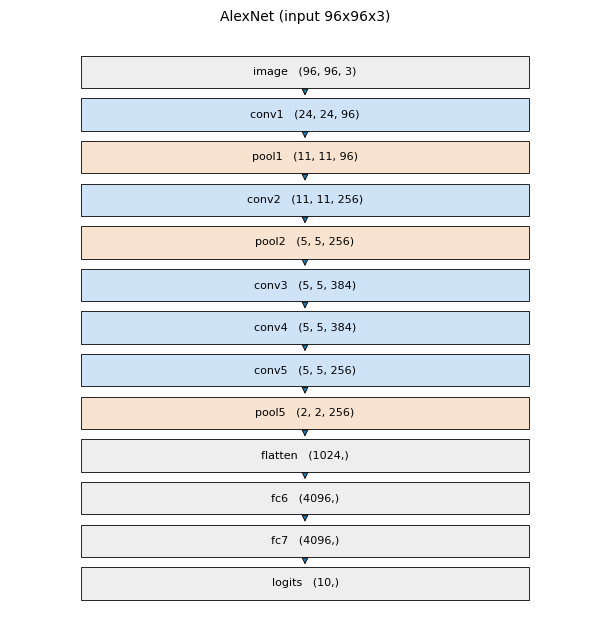

[AlexNet] params trainable/total = 24,767,882/24,767,882 | manual check conv2: 5*5*96*256 + 256 = 614,656 == Keras 614,656



Model: "VGG16"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 96, 96, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 96, 96, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼─

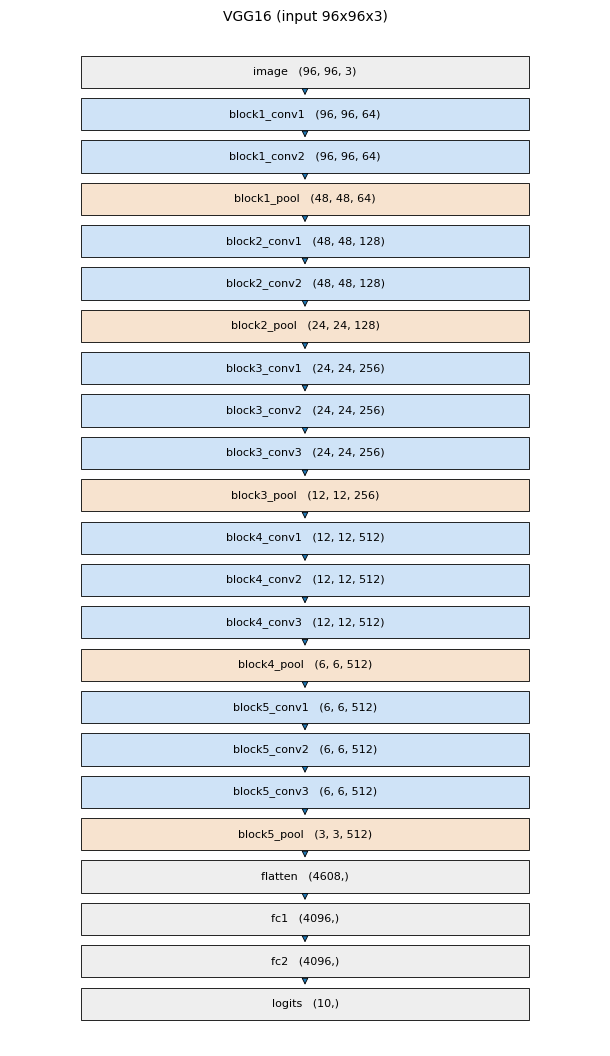

[VGG16] params trainable/total = 50,415,434/50,415,434 | manual check block3_conv1: 3*3*128*256 + 256 = 295,168 == Keras 295,168



Model: "GoogLeNet"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 96, 96, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 96, 96, 3) │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv7x7        │ (None, 48, 48,    │      9,472 │ rescale[0][0]     │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_pool1          │ (None, 24, 24,    │          0 │ stem_conv7x7[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─

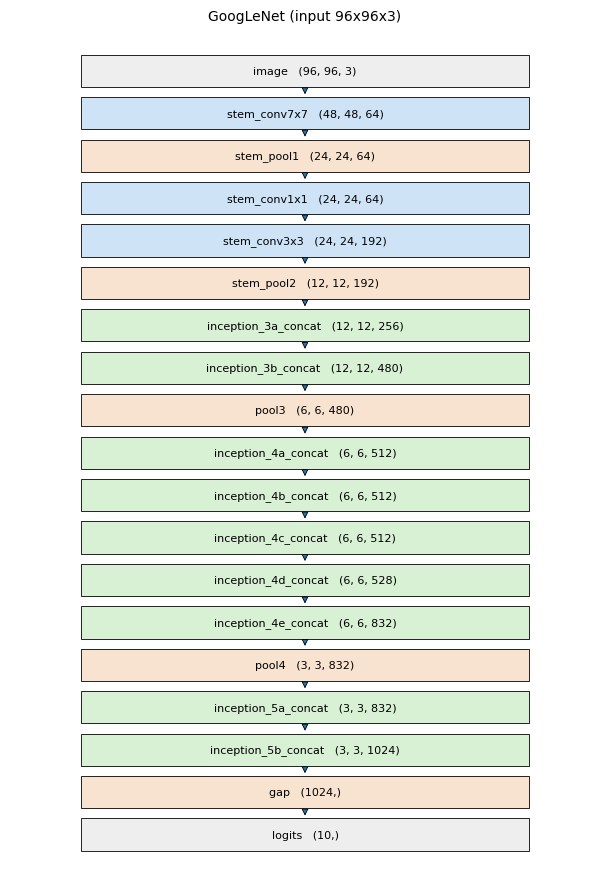

[GoogLeNet] params trainable/total = 5,983,802/5,983,802 | manual check inception_3a_3x3: 3*3*96*128 + 128 = 110,720 == Keras 110,720



Model: "ResNet18"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 96, 96, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 96, 96, 3) │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 48, 48,    │      9,408 │ rescale[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 48, 48,    │        256 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼──

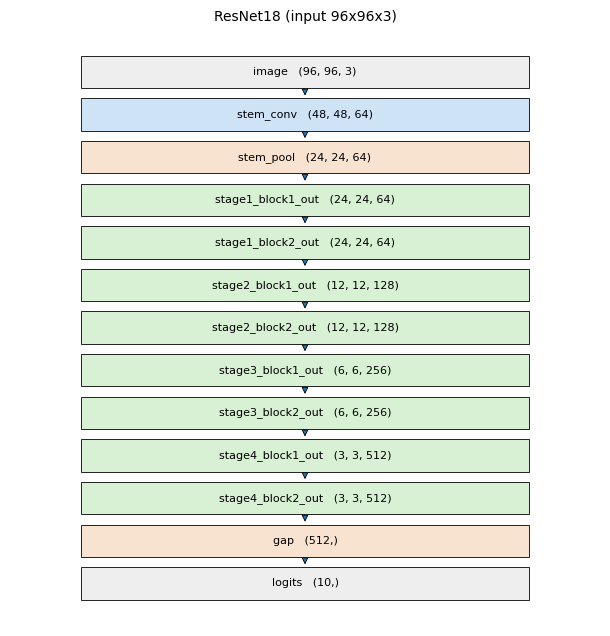

[ResNet18] params trainable/total = 11,181,642/11,191,242 | manual check stage2_block1_proj: 1*1*64*128 (no bias) = 8,192 == Keras 8,192

{
 "conv_stack": 14714688,
 "fc_head_96px": 35700746,
 "total_fc_head_96px": 50415434,
 "total_gap_dense10": 14719818,
 "total_gap_2fc": 33638218,
 "total_fc_head_224px_1000cls": 138357544
}


In [ ]:
def block_diagram(model, select, path, title):
    # simple vertical block diagram (matplotlib) built from the real layers: label + output shape
    rows = [(l.name, tuple(l.output.shape[1:])) for l in model.layers if select(l)]
    fig_h = max(4, 0.42 * len(rows) + 1)
    fig, ax = plt.subplots(figsize=(6.2, fig_h)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, len(rows) + 1)
    for i, (n, s) in enumerate(rows):
        y = len(rows) - i
        col = "#cfe3f7" if ("conv" in n or "1x1" in n or "3x3" in n or "5x5" in n or "proj" in n) else \
              "#f7e3cf" if ("pool" in n or "gap" in n) else "#d8f0d4" if ("concat" in n or "add" in n or "out" in n) else "#eeeeee"
        ax.add_patch(plt.Rectangle((0.12, y - 0.38), 0.76, 0.76, fc=col, ec="k", lw=0.6))
        ax.text(0.5, y, f"{n}   {s}", ha="center", va="center", fontsize=8)
        if i: ax.annotate("", (0.5, y + 0.38), (0.5, y + 0.62), arrowprops=dict(arrowstyle="-|>", lw=0.6))
    ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.show(); plt.close(fig)

DIAGRAM_SELECT = {
    "AlexNet":   lambda l: not isinstance(l, (layers.Dropout, layers.Rescaling)),
    "VGG16":     lambda l: not isinstance(l, (layers.Dropout, layers.Rescaling)),
    "GoogLeNet": lambda l: l.name.startswith("stem_") or l.name.endswith("_concat") or l.name in ("image", "pool3", "pool4", "gap", "logits"),
    "ResNet18":  lambda l: l.name in ("image", "stem_conv", "stem_pool", "gap", "logits") or l.name.endswith("_out"),
}
STRUCT = {}
bench_shape = (IMG_BENCH, IMG_BENCH, 3)
for name, builder in M.ARCHITECTURES.items():
    keras.backend.clear_session()
    model = builder(bench_shape)
    lines = []; model.summary(print_fn=lambda s, **k: lines.append(s))
    (LOGS / f"summary_{name}.txt").write_text("\n".join(lines))
    print("\n".join(lines[:6]), "\n ... (full summary saved to", LOGS / f"summary_{name}.txt", ")")
    # (b) forward pass: 2 x 96 x 96 x 3 -> 2 x 10 logits
    out = model(np.zeros((2, *bench_shape), "float32"))
    assert tuple(out.shape) == (2, 10), out.shape
    trainable, total = M.count_params(model)
    n_conv = sum(isinstance(l, layers.Conv2D) for l in model.layers)
    n_dense = sum(isinstance(l, layers.Dense) for l in model.layers)
    STRUCT[name] = {"forward_shape": [2, 10], "trainable_params": trainable, "total_params": total,
                    "n_conv": n_conv, "n_dense": n_dense}
    block_diagram(model, DIAGRAM_SELECT[name], FIG / f"arch_{name}.png", f"{name} (input {IMG_BENCH}x{IMG_BENCH}x3)")
    try:   # optional Keras graph diagram (needs graphviz); the matplotlib diagram above is always produced
        keras.utils.plot_model(model, to_file=str(FIG / f"arch_{name}_keras.png"), show_shapes=True, dpi=50)
    except Exception as e:
        print("plot_model skipped:", type(e).__name__)

    # (c) one manually checked parameter count
    if name == "AlexNet":
        layer, formula, manual = "conv2", "5*5*96*256 + 256", 5*5*96*256 + 256
        # stage shapes + the adaptation rationale for 96x96 (see report): conv1 same-pad -> 24, pool 11, conv2 11, pool 5, conv3-5 5, pool 2
        STRUCT[name]["stage_shapes"] = M.stage_shapes(model, ["conv", "pool", "fc", "logits"])
        assert [s for n, s in STRUCT[name]["stage_shapes"] if n == "pool5"][0] == (None, 2, 2, 256)
    elif name == "VGG16":
        layer, formula, manual = "block3_conv1", "3*3*128*256 + 256", 3*3*128*256 + 256
        assert n_conv == 13 and n_dense == 3, (n_conv, n_dense)                      # 13 conv + 3 dense
        assert [sum(isinstance(l, layers.Conv2D) and l.name.startswith(f"block{b}_") for l in model.layers) for b in range(1, 6)] == [2, 2, 3, 3, 3]
    elif name == "GoogLeNet":
        layer, formula, manual = "inception_3a_3x3", "3*3*96*128 + 128", 3*3*96*128 + 128
        STRUCT[name]["n_inception_modules"] = sum(l.name.endswith("_concat") for l in model.layers)
        assert STRUCT[name]["n_inception_modules"] == 9
        STRUCT[name]["inception_shapes"] = M.stage_shapes(model, ["_concat"])
    else:
        layer, formula, manual = "stage2_block1_proj", "1*1*64*128 (no bias)", 1*1*64*128
        adds = [l for l in model.layers if isinstance(l, layers.Add)]
        assert len(adds) == 8
        for l in adds:                                     # Add-shape assertions on the finished graph
            shapes = [tuple(t.shape[1:]) for t in l.input]
            assert shapes[0] == shapes[1], (l.name, shapes)
        STRUCT[name]["add_shapes"] = [(l.name, tuple(l.output.shape[1:])) for l in adds]
        STRUCT[name]["n_projection_shortcuts"] = sum(l.name.endswith("_proj") for l in model.layers)
    keras_val = model.get_layer(layer).count_params()
    assert keras_val == manual, (name, keras_val, manual)
    STRUCT[name]["manual_check"] = {"layer": layer, "formula": formula, "manual": manual, "keras": keras_val}
    print(f"[{name}] params trainable/total = {trainable:,}/{total:,} | manual check {layer}: {formula} = {manual:,} == Keras {keras_val:,}\n")

# ---- VGG16: independent cross-check against keras.applications (weights=None -> nothing is downloaded or reused)
ref = keras.applications.VGG16(weights=None, include_top=False, input_shape=bench_shape)
mine = M.build_vgg16(bench_shape)
my_conv = [(l.filters, l.kernel_size) for l in mine.layers if isinstance(l, layers.Conv2D)]
ref_conv = [(l.filters, l.kernel_size) for l in ref.layers if isinstance(l, layers.Conv2D)]
assert my_conv == ref_conv, "manual VGG16 conv stack differs from keras.applications.VGG16"
my_conv_params = sum(l.count_params() for l in mine.layers if isinstance(l, layers.Conv2D))
assert my_conv_params == ref.count_params() == 14_714_688
# ---- VGG16 classifier head: FC head vs GAP head (analytical; the GAP variant is NOT trained)
fc_in = 3 * 3 * 512                                                          # 96 -> 5 pools -> 3x3x512
head_fc   = (fc_in*4096 + 4096) + (4096*4096 + 4096) + (4096*10 + 10)
head_gap  = 512*10 + 10
head_gap2 = (512*4096 + 4096) + (4096*4096 + 4096) + (4096*10 + 10)
vgg_cmp = {"conv_stack": my_conv_params, "fc_head_96px": head_fc, "total_fc_head_96px": my_conv_params + head_fc,
           "total_gap_dense10": my_conv_params + head_gap, "total_gap_2fc": my_conv_params + head_gap2,
           "total_fc_head_224px_1000cls": my_conv_params + (7*7*512*4096 + 4096) + (4096*4096 + 4096) + (4096*1000 + 1000)}
assert vgg_cmp["total_fc_head_96px"] == STRUCT["VGG16"]["total_params"]
assert vgg_cmp["total_gap_dense10"] == M.count_params(M.build_vgg16(bench_shape, head="gap"))[1]
STRUCT["VGG16"]["head_comparison"] = vgg_cmp
print(json.dumps(vgg_cmp, indent=1))
json.dump(STRUCT, open(OUT / "structure_checks.json", "w"), indent=2, default=str)

## 5. Training utilities
* identical checkpoint rule for every run: keep the weights of the epoch with the **highest validation accuracy**; all reported metrics come from that checkpoint
* `final train accuracy` is measured in **inference mode** on the training subset with the selected checkpoint (so dropout / augmentation / BN-batch-statistics do not distort it); generalisation gap = train acc − val acc
* batch 32 is tried first, batch 16 on OOM; every attempt is logged. Models are cleared between runs.

In [ ]:
def cleanup():
    keras.backend.clear_session(); gc.collect()

def gpu_peak_mib():
    try:
        return tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
    except Exception:
        return float("nan")

def reset_gpu_peak():
    try:
        tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception:
        pass

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])

RESULTS = {}
if RESULTS_JSON.exists() and not FORCE_RERUN:
    RESULTS = {r["run_id"]: r for r in json.load(open(RESULTS_JSON))}
    print("resuming - already finished:", [k for k, v in RESULTS.items() if v["status"] == "ok"])

ROW_COLUMNS = ["run_id", "architecture_variant", "input_size", "seed", "trainable_params", "total_params", "epochs",
               "best_val_acc", "macro_f1", "final_train_acc", "generalization_gap", "training_minutes",
               "peak_gpu_mem_mib", "batch_size", "learning_rate", "best_epoch", "status", "attempted_batch_sizes", "caveat"]

def save_results():
    rows = sorted(RESULTS.values(), key=lambda r: r["order"])
    json.dump(rows, open(RESULTS_JSON, "w"), indent=1, default=str)
    pd.DataFrame(rows)[[c for c in ROW_COLUMNS if c in rows[0]]].to_csv(RESULTS_CSV, index=False)

def _train_once(spec, bs):
    cleanup(); set_all_seeds(spec["seed"])
    size = spec["size"]
    train_ds = make_dataset(x_tr, y_tr, size, bs, True, spec["seed"])
    val_ds = make_dataset(x_va, y_va, size, bs, False)
    model = spec["build"]()
    if spec["init_from"]:
        model.load_weights(CKPT / f"{spec['init_from']}.weights.h5")        # A4-T starts from the A4-F best checkpoint
    if spec["post_build"]:
        spec["post_build"](model)                                            # e.g. unfreeze top ResNet50 stage
    compile_model(model, spec["lr"])                                         # (re)compile AFTER any trainable-flag change
    trainable, total = M.count_params(model)
    ckpt_path = CKPT / f"{spec['run_id']}.weights.h5"
    if ckpt_path.exists(): ckpt_path.unlink()
    cbs = [keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_accuracy", mode="max",
                                           save_best_only=True, save_weights_only=True),
           keras.callbacks.TerminateOnNaN()]
    reset_gpu_peak(); t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=spec["epochs"], callbacks=cbs, verbose=2)
    minutes = (time.time() - t0) / 60
    peak = gpu_peak_mib()
    h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    json.dump(h, open(HIST / f"{spec['run_id']}.json", "w"))
    if not ckpt_path.exists():
        raise RuntimeError("no checkpoint written (loss became NaN in the first epoch)")
    model.load_weights(ckpt_path)                                            # best-val-accuracy checkpoint
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    pred = np.argmax(model.predict(val_ds, verbose=0), axis=1)
    macro_f1 = f1_score(y_va, pred, average="macro")
    _, train_acc = model.evaluate(make_dataset(x_tr, y_tr, size, bs, False), verbose=0)
    finite = all(np.isfinite(h["loss"]))
    row = dict(run_id=spec["run_id"], architecture_variant=spec["variant"], input_size=f"{size}x{size}", seed=spec["seed"],
               trainable_params=trainable, total_params=total, epochs=len(h["loss"]),
               best_val_acc=float(val_acc), macro_f1=float(macro_f1), final_train_acc=float(train_acc),
               generalization_gap=float(train_acc - val_acc), training_minutes=float(minutes), peak_gpu_mem_mib=float(peak),
               batch_size=bs, learning_rate=spec["lr"], best_epoch=int(np.argmax(h["val_accuracy"]) + 1),
               status="ok" if finite else "nan_loss", caveat=spec["caveat"], order=spec["order"], group=spec["group"])
    del model; cleanup()
    return row

def run_experiment(run_id):
    spec = SPECS[run_id]
    if not FORCE_RERUN and run_id in RESULTS and RESULTS[run_id]["status"] == "ok":
        print(f"[skip] {run_id} already finished"); return RESULTS[run_id]
    if spec["init_from"] and RESULTS.get(spec["init_from"], {}).get("status") != "ok":
        row = dict(run_id=run_id, architecture_variant=spec["variant"], input_size=f"{spec['size']}x{spec['size']}", seed=spec["seed"],
                   status=f"skipped: prerequisite {spec['init_from']} did not finish", caveat=spec["caveat"],
                   order=spec["order"], group=spec["group"], attempted_batch_sizes="-")
        RESULTS[run_id] = row; save_results(); return row
    print(f"\n===== {run_id} : {spec['variant']} | {spec['size']}x{spec['size']} | seed {spec['seed']} | {spec['epochs']} epochs | lr {spec['lr']} =====")
    attempts, row = [], None
    for bs in BATCH_CANDIDATES:
        try:
            row = _train_once(spec, bs); attempts.append(f"{bs}: ok"); break
        except tf.errors.ResourceExhaustedError:
            attempts.append(f"{bs}: OOM"); print(f"!! OOM at batch {bs} -> trying next batch size"); cleanup()
        except Exception as e:
            attempts.append(f"{bs}: {type(e).__name__}: {str(e)[:120]}"); print("!! run failed:", repr(e)); cleanup(); break
    if row is None:
        row = dict(run_id=run_id, architecture_variant=spec["variant"], input_size=f"{spec['size']}x{spec['size']}", seed=spec["seed"],
                   status="failed (see attempted_batch_sizes)", caveat=spec["caveat"], order=spec["order"], group=spec["group"])
    row["attempted_batch_sizes"] = " | ".join(attempts)
    RESULTS[run_id] = row; save_results()
    (LOGS / "run_log.jsonl").open("a").write(json.dumps(row, default=str) + "\n")      # failed runs are never deleted
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items() if k in
           ("best_val_acc", "macro_f1", "final_train_acc", "generalization_gap", "training_minutes", "peak_gpu_mem_mib", "batch_size", "status")})
    return row

## 6. Learning-rate sanity check (before the main runs)
1 epoch on the first 3 000 training images, three Adam learning rates, each of the four architectures at 96×96, batch 32.
The benchmark keeps the assignment's common Adam 3e-4 unless it **diverges (NaN / loss exploding)** for some architecture – in that case the largest non-diverging candidate below 3e-4 is used.
Validation accuracy is printed for information only and is *not* used to tune the learning rate.

In [ ]:
def lr_sanity_check():
    rows = []
    n = min(3000, len(x_tr))
    for name, builder in M.ARCHITECTURES.items():
        for lr in LR_CANDIDATES:
            cleanup(); set_all_seeds(SEED)
            model = builder((IMG_BENCH, IMG_BENCH, 3)); compile_model(model, lr)
            try:
                h = model.fit(make_dataset(x_tr[:n], y_tr[:n], IMG_BENCH, 32, True), validation_data=make_dataset(x_va, y_va, IMG_BENCH, 32, False),
                              epochs=1, verbose=0, callbacks=[keras.callbacks.TerminateOnNaN()])
                loss, vacc = h.history["loss"][-1], h.history["val_accuracy"][-1]
            except tf.errors.ResourceExhaustedError:
                loss, vacc = float("nan"), float("nan")
            diverged = (not np.isfinite(loss)) or loss > 5.0
            rows.append(dict(architecture=name, lr=lr, train_loss_1ep=float(loss), val_acc_1ep=float(vacc), diverged=bool(diverged)))
            del model
    return pd.DataFrame(rows)

lr_df = lr_sanity_check(); lr_df.to_csv(OUT / "lr_sanity_check.csv", index=False)
print(lr_df.to_string(index=False))
if lr_df[(lr_df.lr == 3e-4)].diverged.any():
    ok_lrs = [lr for lr in LR_CANDIDATES if lr < 3e-4 and not lr_df[lr_df.lr == lr].diverged.any()]
    COMMON_LR = max(ok_lrs) if ok_lrs else min(LR_CANDIDATES)
    print("!! 3e-4 diverged for some architecture -> COMMON_LR set to", COMMON_LR)
else:
    print("OK: Adam 3e-4 does not diverge for any architecture -> COMMON_LR = 3e-4")
ENV["common_lr_after_sanity_check"] = COMMON_LR
json.dump(ENV, open(OUT / "environment.json", "w"), indent=2)

architecture     lr  train_loss_1ep  val_acc_1ep  diverged
     AlexNet 0.0001        2.269627     0.325667     False
     AlexNet 0.0003        2.248343     0.226333     False
     AlexNet 0.0010        2.434600     0.178667     False
       VGG16 0.0001        2.349508     0.107333     False
       VGG16 0.0003        2.391141     0.111000     False
       VGG16 0.0010        3.587728     0.100000     False
   GoogLeNet 0.0001        2.266551     0.174333     False
   GoogLeNet 0.0003        2.281155     0.105667     False
   GoogLeNet 0.0010        2.336896     0.096667     False
    ResNet18 0.0001        1.939954     0.202000     False
    ResNet18 0.0003        1.878402     0.176667     False
    ResNet18 0.0010        1.929892     0.164333     False
OK: Adam 3e-4 does not diverge for any architecture -> COMMON_LR = 3e-4


## 7. Experiment registry (every run is declared here: architecture, resolution, seed, epochs, LR)

In [ ]:
SPECS, _order = {}, [0]
def add_spec(run_id, group, variant, build, size, seed, epochs, lr, caveat, init_from=None, post_build=None):
    _order[0] += 1
    SPECS[run_id] = dict(run_id=run_id, group=group, variant=variant, build=build, size=size, seed=seed, epochs=epochs,
                         lr=lr, caveat=caveat, init_from=init_from, post_build=post_build, order=_order[0])

ARCH_CAVEAT = "Single seed; 32->96 upsampled; no augmentation; params/FLOPs differ across models (equal epochs only)"
for name, fn in M.ARCHITECTURES.items():
    add_spec(f"ARCH_{name}", "architecture", name, (lambda fn=fn: fn((IMG_BENCH, IMG_BENCH, 3))), IMG_BENCH, SEED, EPOCHS_ARCH, COMMON_LR, ARCH_CAVEAT)

ABL_CAVEAT = {"A0": "Reference baseline", "A1": "A0 + BatchNorm only", "A2": "A1 + augmentation only",
              "A3P": "Deeper/larger than A2 (more params) - not a one-factor step from A2",
              "A3R": "A3-P + shortcuts only (adds 1x1 projection weights)"}
ABL_NAME = {"A0": "A0 baseline", "A1": "A1 (+BN)", "A2": "A2 (+augmentation)", "A3P": "A3-P (deeper plain)", "A3R": "A3-R (residual)"}
for seed in SEEDS_ABLATION:
    for key, fn in M.ABLATIONS.items():
        add_spec(f"{key}_s{seed}", "ablation", ABL_NAME[key], (lambda fn=fn: fn((IMG_ABL, IMG_ABL, 3))), IMG_ABL, seed, EPOCHS_ABL, COMMON_LR, ABL_CAVEAT[key])
add_spec("A4F_s42", "transfer", "A4-F (frozen ResNet50)", (lambda: M.build_a4((IMG_A4, IMG_A4, 3), weights=A4_WEIGHTS)), IMG_A4, SEED, EPOCHS_A4F, COMMON_LR,
         "SEPARATE transfer branch: ImageNet init + external data, 96x96, ResNet50 trunk frozen - not a one-factor step from A3")
add_spec("A4T_s42", "transfer", "A4-T (fine-tuned top stage)", (lambda: M.build_a4((IMG_A4, IMG_A4, 3), weights=A4_WEIGHTS)), IMG_A4, SEED, EPOCHS_A4T, LR_FINETUNE,
         "A4-F + conv5 stage unfrozen (BN frozen), LR 1e-5; also gets more total epochs than A4-F",
         init_from="A4F_s42", post_build=M.unfreeze_resnet50_top)
print(len(SPECS), "runs registered:", list(SPECS))

16 runs registered: ['ARCH_AlexNet', 'ARCH_VGG16', 'ARCH_GoogLeNet', 'ARCH_ResNet18', 'A0_s42', 'A1_s42', 'A2_s42', 'A3P_s42', 'A3R_s42', 'A0_s123', 'A1_s123', 'A2_s123', 'A3P_s123', 'A3R_s123', 'A4F_s42', 'A4T_s42']


## 8. Part II runs – AlexNet, VGG16, GoogLeNet, ResNet-18 (96×96, 5 epochs, seed 42, Adam, no augmentation)

In [ ]:
for name in M.ARCHITECTURES:
    run_experiment(f"ARCH_{name}")
pd.DataFrame([RESULTS[f"ARCH_{n}"] for n in M.ARCHITECTURES])[[c for c in ROW_COLUMNS if c != "caveat"]]


===== ARCH_AlexNet : AlexNet | 96x96 | seed 42 | 5 epochs | lr 0.0003 =====
Epoch 1/5
375/375 - 15s - 40ms/step - accuracy: 0.3052 - loss: 1.8616 - val_accuracy: 0.4487 - val_loss: 1.5027
Epoch 2/5
375/375 - 8s - 22ms/step - accuracy: 0.4630 - loss: 1.4555 - val_accuracy: 0.5100 - val_loss: 1.3424
Epoch 3/5
375/375 - 13s - 35ms/step - accuracy: 0.5445 - loss: 1.2625 - val_accuracy: 0.5167 - val_loss: 1.3560
Epoch 4/5
375/375 - 13s - 34ms/step - accuracy: 0.6135 - loss: 1.0777 - val_accuracy: 0.5420 - val_loss: 1.3161
Epoch 5/5
375/375 - 14s - 37ms/step - accuracy: 0.6706 - loss: 0.9194 - val_accuracy: 0.6070 - val_loss: 1.1350
{'best_val_acc': 0.607, 'macro_f1': 0.6054, 'final_train_acc': 0.7514, 'generalization_gap': 0.1444, 'training_minutes': 1.0548, 'peak_gpu_mem_mib': 4218.5483, 'batch_size': 32, 'status': 'ok'}

===== ARCH_VGG16 : VGG16 | 96x96 | seed 42 | 5 epochs | lr 0.0003 =====
Epoch 1/5
375/375 - 57s - 151ms/step - accuracy: 0.1997 - loss: 2.1460 - val_accuracy: 0.2997 - v

,run_id,architecture_variant,input_size,seed,trainable_params,total_params,epochs,best_val_acc,macro_f1,final_train_acc,generalization_gap,training_minutes,peak_gpu_mem_mib,batch_size,learning_rate,best_epoch,status,attempted_batch_sizes
0,ARCH_AlexNet,AlexNet,96x96,42,24767882,24767882,5,0.607000,0.605413,0.751417,0.144417,1.054807,4218.548340,32,0.0003,5,ok,32: ok
1,ARCH_VGG16,VGG16,96x96,42,50415434,50415434,5,0.532333,0.523988,0.590917,0.058583,4.319729,5616.340576,32,0.0003,5,ok,32: ok
2,ARCH_GoogLeNet,GoogLeNet,96x96,42,5983802,5983802,5,0.546000,0.541873,0.619250,0.073250,1.737382,4958.720947,32,0.0003,5,ok,32: ok
3,ARCH_ResNet18,ResNet18,96x96,42,11181642,11191242,5,0.540000,0.542126,0.870583,0.330583,1.424578,5055.447998,32,0.0003,5,ok,32: ok


## 9. Part III – controlled ablation (64×64) and the separate transfer branch
A0 → A1 → A2 are additive one-factor steps. A3-P → A3-R keeps depth, widths, BN, augmentation and optimiser identical (only shortcuts differ).
A4 changes initialisation *and* the external data source and is therefore reported as a **separate branch**, not as a one-factor increment.

In [ ]:
for seed in SEEDS_ABLATION:
    for key in M.ABLATIONS:
        run_experiment(f"{key}_s{seed}")
pd.DataFrame([RESULTS[f"{k}_s{s}"] for s in SEEDS_ABLATION for k in M.ABLATIONS])[[c for c in ROW_COLUMNS if c != "caveat"]]


===== A0_s42 : A0 baseline | 64x64 | seed 42 | 10 epochs | lr 0.0003 =====
Epoch 1/10
375/375 - 10s - 27ms/step - accuracy: 0.1799 - loss: 2.2003 - val_accuracy: 0.2260 - val_loss: 2.0848
Epoch 2/10
375/375 - 3s - 8ms/step - accuracy: 0.2382 - loss: 2.0459 - val_accuracy: 0.2750 - val_loss: 2.0268
Epoch 3/10
375/375 - 3s - 7ms/step - accuracy: 0.2651 - loss: 1.9917 - val_accuracy: 0.2733 - val_loss: 1.9778
Epoch 4/10
375/375 - 2s - 6ms/step - accuracy: 0.2849 - loss: 1.9494 - val_accuracy: 0.2773 - val_loss: 1.9404
Epoch 5/10
375/375 - 3s - 7ms/step - accuracy: 0.3008 - loss: 1.9166 - val_accuracy: 0.3053 - val_loss: 1.9054
Epoch 6/10
375/375 - 2s - 6ms/step - accuracy: 0.3132 - loss: 1.8897 - val_accuracy: 0.3040 - val_loss: 1.8854
Epoch 7/10
375/375 - 3s - 7ms/step - accuracy: 0.3183 - loss: 1.8651 - val_accuracy: 0.2910 - val_loss: 1.8694
Epoch 8/10
375/375 - 3s - 7ms/step - accuracy: 0.3225 - loss: 1.8513 - val_accuracy: 0.3227 - val_loss: 1.8436
Epoch 9/10
375/375 - 2s - 6ms/step

,run_id,architecture_variant,input_size,seed,trainable_params,total_params,epochs,best_val_acc,macro_f1,final_train_acc,generalization_gap,training_minutes,peak_gpu_mem_mib,batch_size,learning_rate,best_epoch,status,attempted_batch_sizes
0,A0_s42,A0 baseline,64x64,42,20042,20042,10,0.340000,0.305142,0.347917,0.007917,0.545336,5070.714111,32,0.0003,10,ok,32: ok
1,A1_s42,A1 (+BN),64x64,42,20234,20426,10,0.434667,0.412470,0.430083,-0.004583,0.754712,4984.344971,32,0.0003,8,ok,32: ok
2,A2_s42,A2 (+augmentation),64x64,42,20234,20426,10,0.425000,0.406046,0.436833,0.011833,1.100565,5089.866211,32,0.0003,8,ok,32: ok
3,A3P_s42,A3-P (deeper plain),64x64,42,686922,688778,10,0.678667,0.669188,0.715333,0.036667,4.489881,5396.237305,32,0.0003,10,ok,32: ok
4,A3R_s42,A3-R (residual),64x64,42,697546,699786,10,0.653000,0.647342,0.706917,0.053917,5.271033,5195.142578,32,0.0003,8,ok,32: ok
5,A0_s123,A0 baseline,64x64,123,20042,20042,10,0.345667,0.332555,0.353000,0.007333,0.460570,4962.775391,32,0.0003,9,ok,32: ok
6,A1_s123,A1 (+BN),64x64,123,20234,20426,10,0.449333,0.433372,0.450917,0.001583,0.553749,4963.093262,32,0.0003,10,ok,32: ok
7,A2_s123,A2 (+augmentation),64x64,123,20234,20426,10,0.435667,0.415369,0.440167,0.004500,1.112598,4981.237549,32,0.0003,8,ok,32: ok
8,A3P_s123,A3-P (deeper plain),64x64,123,686922,688778,10,0.685667,0.685858,0.733500,0.047833,4.223154,5199.588135,32,0.0003,10,ok,32: ok
9,A3R_s123,A3-R (residual),64x64,123,697546,699786,10,0.643333,0.640406,0.693083,0.049750,4.530391,5205.052490,32,0.0003,10,ok,32: ok


In [ ]:
# A4-F: ImageNet-pretrained ResNet50 trunk frozen, called with training=False (BN in inference mode), preprocess_input applied on 0-255 pixels.
# A4-T: starts from the A4-F best checkpoint, unfreezes the conv5 stage (BN layers stay frozen), RE-COMPILES, Adam 1e-5.
run_experiment("A4F_s42")
run_experiment("A4T_s42")
pd.DataFrame([RESULTS[k] for k in ("A4F_s42", "A4T_s42")])[[c for c in ROW_COLUMNS if c != "caveat"]]


===== A4F_s42 : A4-F (frozen ResNet50) | 96x96 | seed 42 | 5 epochs | lr 0.0003 =====
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
375/375 - 29s - 77ms/step - accuracy: 0.6653 - loss: 1.0604 - val_accuracy: 0.7980 - val_loss: 0.6165
Epoch 2/5
375/375 - 18s - 47ms/step - accuracy: 0.8049 - loss: 0.5857 - val_accuracy: 0.8247 - val_loss: 0.5289
Epoch 3/5
375/375 - 18s - 47ms/step - accuracy: 0.8329 - loss: 0.4980 - val_accuracy: 0.8353 - val_loss: 0.4958
Epoch 4/5
375/375 - 17s - 46ms/step - accuracy: 0.8517 - loss: 0.4445 - val_accuracy: 0.8413 - val_loss: 0.4932
Epoch 5/5
375/375 - 17s - 44ms/step - accuracy: 0.8597 - loss: 0.4081 - val_accuracy: 0.8497 - val_loss: 0.4608
{'best_val_acc': 0.8497, 'macro_f1': 0.8496, 'final_train_acc': 0.8838, 'generalization_gap': 0.0341, 'training_minutes': 1.6375, 'peak_gpu_mem_mib': 5226.2151, 'batch_size': 32, 'status': 'ok'}

===== A4T_s42 : A4-T (fine-tuned top stage) | 96x96 | seed 42 | 5 epochs | lr 1e-05 =====
Epoch 1/5
375/37

,run_id,architecture_variant,input_size,seed,trainable_params,total_params,epochs,best_val_acc,macro_f1,final_train_acc,generalization_gap,training_minutes,peak_gpu_mem_mib,batch_size,learning_rate,best_epoch,status,attempted_batch_sizes
0,A4F_s42,A4-F (frozen ResNet50),96x96,42,20490,23608202,5,0.849667,0.849592,0.88375,0.034083,1.637546,5226.215088,32,0.00030,5,ok,32: ok
1,A4T_s42,A4-T (fine-tuned top stage),96x96,42,14973962,23608202,5,0.881000,0.880860,0.97350,0.092500,2.859826,6432.266113,32,0.00001,5,ok,32: ok


## 10. Part IV – results table, figures and analysis

In [ ]:
df = pd.DataFrame(sorted(RESULTS.values(), key=lambda r: r["order"]))
table = df.assign(**{"trainable/total params": df.get("trainable_params").map("{:,.0f}".format) + " / " + df.get("total_params").map("{:,.0f}".format)})
show = ["run_id", "architecture_variant", "input_size", "seed", "trainable/total params", "epochs", "best_val_acc", "macro_f1",
        "final_train_acc", "generalization_gap", "training_minutes", "peak_gpu_mem_mib", "caveat"]
pd.set_option("display.width", 250, "display.max_colwidth", 60)
print(table[[c for c in show if c in table]].round(4).to_string(index=False))
print("\nFailed / skipped / OOM-affected runs (kept in logs, never replaced by invented numbers):")
bad = df[(df.status != "ok") | df.attempted_batch_sizes.astype(str).str.contains("OOM")]
print(bad[["run_id", "status", "attempted_batch_sizes"]].to_string(index=False) if len(bad) else "none")

        run_id        architecture_variant input_size  seed  trainable/total params  epochs  best_val_acc  macro_f1  final_train_acc  generalization_gap  training_minutes  peak_gpu_mem_mib                                                                                                                caveat
  ARCH_AlexNet                     AlexNet      96x96    42 24,767,882 / 24,767,882       5        0.6070    0.6054           0.7514              0.1444            1.0548         4218.5483                 Single seed; 32->96 upsampled; no augmentation; params/FLOPs differ across models (equal epochs only)
    ARCH_VGG16                       VGG16      96x96    42 50,415,434 / 50,415,434       5        0.5323    0.5240           0.5909              0.0586            4.3197         5616.3406                 Single seed; 32->96 upsampled; no augmentation; params/FLOPs differ across models (equal epochs only)
ARCH_GoogLeNet                   GoogLeNet      96x96    42   5,983,802 / 5,983

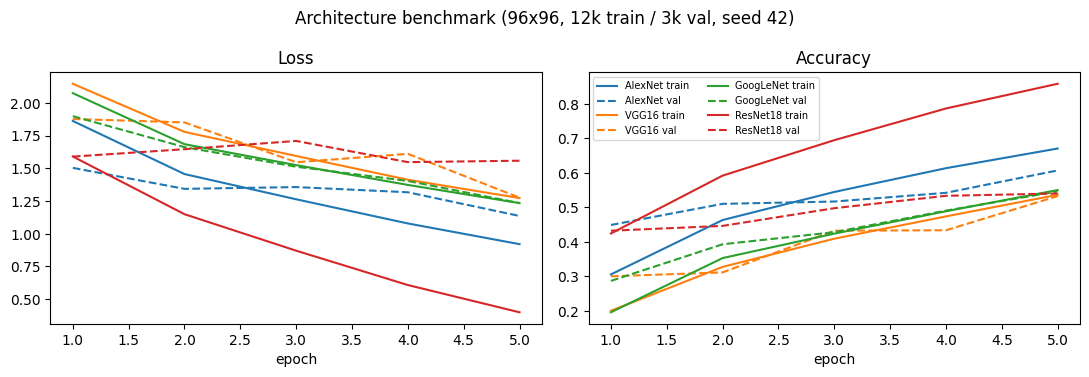

               variant  n_seeds  val_acc_mean  val_acc_std  macro_f1_mean  gap_mean  params_total  minutes_mean
           A0 baseline        2        0.3428       0.0040         0.3188    0.0076         20042        0.5030
              A1 (+BN)        2        0.4420       0.0104         0.4229   -0.0015         20426        0.6542
    A2 (+augmentation)        2        0.4303       0.0075         0.4107    0.0082         20426        1.1066
   A3-P (deeper plain)        2        0.6822       0.0049         0.6775    0.0423        688778        4.3565
       A3-R (residual)        2        0.6482       0.0068         0.6439    0.0518        699786        4.9007
A4-F (separate branch)        1        0.8497          NaN         0.8496    0.0341      23608202        1.6375
A4-T (separate branch)        1        0.8810          NaN         0.8809    0.0925      23608202        2.8598
{'A1-A0 (BN)': 0.0992, 'A2-A1 (augmentation)': -0.0117, 'A3P-A2 (depth/capacity, confounded)': 0.2518, '

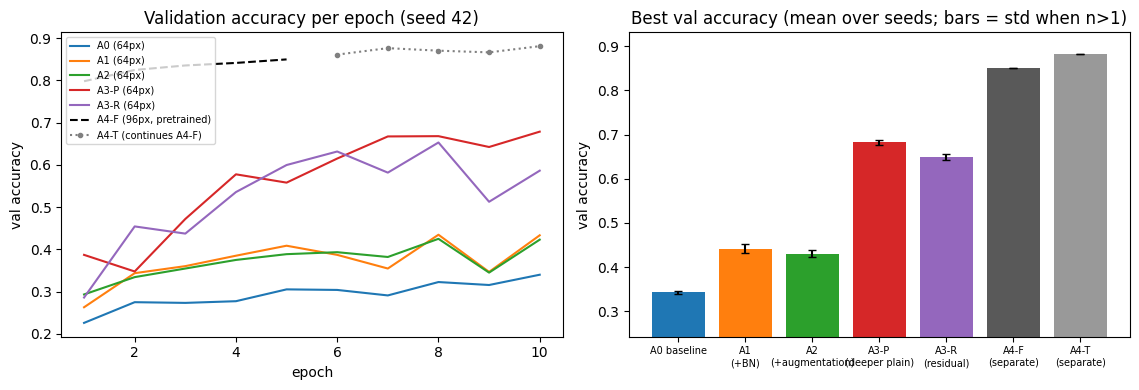

architecture_variant  best_val_acc  training_minutes  total_params  peak_gpu_mem_mib  acc_per_minute
             AlexNet        0.6070            1.0548      24767882         4218.5483          0.5755
               VGG16        0.5323            4.3197      50415434         5616.3406          0.1232
           GoogLeNet        0.5460            1.7374       5983802         4958.7209          0.3143
            ResNet18        0.5400            1.4246      11191242         5055.4480          0.3791
best val accuracy: AlexNet | fastest: AlexNet


In [ ]:
def load_hist(run_id):
    p = HIST / f"{run_id}.json"
    return json.load(open(p)) if p.exists() else None

# ---- Figure 1: train vs validation curves of the four architectures
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, name in enumerate(M.ARCHITECTURES):
    h = load_hist(f"ARCH_{name}")
    if h is None: continue
    ep = range(1, len(h["loss"]) + 1); c = f"C{i}"
    ax[0].plot(ep, h["loss"], c=c, label=f"{name} train"); ax[0].plot(ep, h["val_loss"], c=c, ls="--", label=f"{name} val")
    ax[1].plot(ep, h["accuracy"], c=c, label=f"{name} train"); ax[1].plot(ep, h["val_accuracy"], c=c, ls="--", label=f"{name} val")
ax[0].set(title="Loss", xlabel="epoch"); ax[1].set(title="Accuracy", xlabel="epoch"); ax[1].legend(fontsize=7, ncol=2)
plt.suptitle("Architecture benchmark (96x96, 12k train / 3k val, seed 42)"); plt.tight_layout()
plt.savefig(FIG / "fig_arch_curves.png", dpi=150); plt.show()

# ---- Ablation summary (mean +/- std over seeds) and deltas
abl = df[df.group == "ablation"].copy()
rows = []
for key, label in ABL_NAME.items():
    sub = abl[(abl.architecture_variant == label) & (abl.status == "ok")]
    if len(sub):
        rows.append(dict(variant=label, n_seeds=len(sub), val_acc_mean=sub.best_val_acc.mean(), val_acc_std=sub.best_val_acc.std(ddof=1) if len(sub) > 1 else float("nan"),
                         macro_f1_mean=sub.macro_f1.mean(), gap_mean=sub.generalization_gap.mean(), params_total=int(sub.total_params.iloc[0]), minutes_mean=sub.training_minutes.mean()))
for rid, label in (("A4F_s42", "A4-F (separate branch)"), ("A4T_s42", "A4-T (separate branch)")):
    r = RESULTS.get(rid)
    if r and r["status"] == "ok":
        rows.append(dict(variant=label, n_seeds=1, val_acc_mean=r["best_val_acc"], val_acc_std=float("nan"), macro_f1_mean=r["macro_f1"],
                         gap_mean=r["generalization_gap"], params_total=int(r["total_params"]), minutes_mean=r["training_minutes"]))
abl_sum = pd.DataFrame(rows); abl_sum.to_csv(OUT / "ablation_summary.csv", index=False)
print(abl_sum.round(4).to_string(index=False))
def _m(label):
    s = abl_sum[abl_sum.variant == label]
    return float(s.val_acc_mean.iloc[0]) if len(s) else float("nan")
deltas = {"A1-A0 (BN)": _m("A1 (+BN)") - _m("A0 baseline"), "A2-A1 (augmentation)": _m("A2 (+augmentation)") - _m("A1 (+BN)"),
          "A3P-A2 (depth/capacity, confounded)": _m("A3-P (deeper plain)") - _m("A2 (+augmentation)"),
          "A3R-A3P (shortcuts only)": _m("A3-R (residual)") - _m("A3-P (deeper plain)"),
          "A4T-A4F (fine-tuning)": _m("A4-T (separate branch)") - _m("A4-F (separate branch)")}
json.dump(deltas, open(OUT / "ablation_deltas.json", "w"), indent=2)
print({k: round(v, 4) for k, v in deltas.items()})

# ---- Figure 2: ablation plot (A0, A1, A2, A3-P, A3-R, A4-F, A4-T)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
curve_ids = [("A0_s42", "A0"), ("A1_s42", "A1"), ("A2_s42", "A2"), ("A3P_s42", "A3-P"), ("A3R_s42", "A3-R")]
for i, (rid, lab) in enumerate(curve_ids):
    h = load_hist(rid)
    if h: ax[0].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], c=f"C{i}", label=f"{lab} (64px)")
hf, ht = load_hist("A4F_s42"), load_hist("A4T_s42")
if hf:
    ax[0].plot(range(1, len(hf["val_accuracy"]) + 1), hf["val_accuracy"], c="k", ls="--", label="A4-F (96px, pretrained)")
if hf and ht:
    n0 = len(hf["val_accuracy"]); ax[0].plot(range(n0 + 1, n0 + len(ht["val_accuracy"]) + 1), ht["val_accuracy"], c="gray", ls=":", marker="o", ms=3, label="A4-T (continues A4-F)")
ax[0].set(title="Validation accuracy per epoch (seed 42)", xlabel="epoch", ylabel="val accuracy"); ax[0].legend(fontsize=7)
if len(abl_sum):
    colors = ["C0", "C1", "C2", "C3", "C4", "0.35", "0.6"][:len(abl_sum)]
    ax[1].bar(range(len(abl_sum)), abl_sum.val_acc_mean, yerr=abl_sum.val_acc_std.fillna(0), color=colors, capsize=3,
              hatch=None)
    ax[1].set_xticks(range(len(abl_sum))); ax[1].set_xticklabels([v.replace(" (separate branch)", "\n(separate)").replace(" (", "\n(") for v in abl_sum.variant], fontsize=7)
    lo = max(0, float(abl_sum.val_acc_mean.min()) - 0.1); ax[1].set_ylim(lo, min(1.0, float(abl_sum.val_acc_mean.max()) + 0.05))
    ax[1].set(title="Best val accuracy (mean over seeds; bars = std when n>1)", ylabel="val accuracy")
plt.tight_layout(); plt.savefig(FIG / "fig_ablation.png", dpi=150); plt.show()

# ---- Architecture comparison: why "best accuracy" and "fastest" need not coincide
arch = df[(df.group == "architecture") & (df.status == "ok")].copy()
if len(arch):
    arch["acc_per_minute"] = arch.best_val_acc / arch.training_minutes
    print(arch[["architecture_variant", "best_val_acc", "training_minutes", "total_params", "peak_gpu_mem_mib", "acc_per_minute"]].round(4).to_string(index=False))
    print("best val accuracy:", arch.loc[arch.best_val_acc.idxmax(), "architecture_variant"], "| fastest:", arch.loc[arch.training_minutes.idxmin(), "architecture_variant"])

## 11. Final model: identity recorded **before** the single test evaluation
Rule (fixed in advance): among all successful runs in `WINNER_POOL` choose the highest validation accuracy (ties → fewer parameters).
The choice is written to `final_model_selection.json` first; `evaluate_on_test_once()` refuses to run a second time.

Selected BEFORE test evaluation: {'selected_run_id': 'A4T_s42', 'variant': 'A4-T (fine-tuned top stage)', 'val_acc': 0.8809999823570251, 'rule': 'highest validation accuracy among eligible successful runs; ties -> fewer parameters', 'recorded_at_utc': '2026-11-21T08:27:10+00:00', 'test_evaluated_yet': False}
TEST accuracy 0.8674 | macro-F1 0.8673


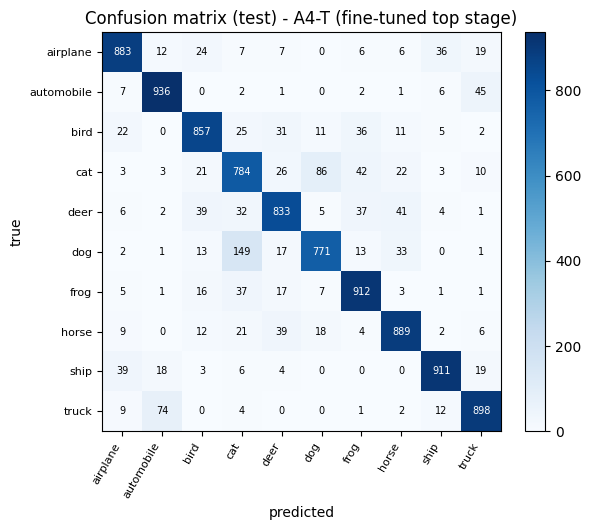

most frequent confusions (true, predicted, count): [('dog', 'cat', 149), ('cat', 'dog', 86), ('truck', 'automobile', 74), ('automobile', 'truck', 45), ('cat', 'frog', 42)]


In [ ]:
SEL_FILE, TEST_FILE = OUT / "final_model_selection.json", OUT / "test_evaluation_once.json"

def select_final_model():
    if SEL_FILE.exists():
        return json.load(open(SEL_FILE))                              # identity already recorded - never changed afterwards
    pool = [r for r in RESULTS.values() if r["status"] == "ok" and (WINNER_POOL is None or r["run_id"] in WINNER_POOL)]
    best = max(pool, key=lambda r: (round(r["best_val_acc"], 6), -r["total_params"]))
    sel = {"selected_run_id": best["run_id"], "variant": best["architecture_variant"], "val_acc": best["best_val_acc"],
           "rule": "highest validation accuracy among eligible successful runs; ties -> fewer parameters",
           "recorded_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "test_evaluated_yet": False}
    json.dump(sel, open(SEL_FILE, "w"), indent=2)
    return sel

def evaluate_on_test_once():
    if TEST_FILE.exists():
        print("Test split was already evaluated once - returning the stored record."); return json.load(open(TEST_FILE))
    sel = select_final_model()
    spec = SPECS[sel["selected_run_id"]]; cleanup()
    model = spec["build"](); model.load_weights(CKPT / f"{spec['run_id']}.weights.h5")
    compile_model(model, spec["lr"])
    xt, yt = TEST_LOCKED["x"], TEST_LOCKED["y"]
    logits = model.predict(make_dataset(xt, yt, spec["size"], 32, False), verbose=0)       # the one and only test pass
    pred = logits.argmax(1)
    acc = float((pred == yt).mean()); f1 = float(f1_score(yt, pred, average="macro"))
    cm = confusion_matrix(yt, pred, labels=range(10))
    rep = classification_report(yt, pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(10) for j in range(10) if i != j]
    rec = {**sel, "test_evaluated_yet": True, "test_accuracy": acc, "test_macro_f1": f1, "confusion_matrix": cm.tolist(),
           "per_class": {k: rep[k] for k in CLASS_NAMES}, "top_confusions_true_pred_count": sorted(off, key=lambda t: -t[2])[:5],
           "evaluated_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")}
    json.dump(rec, open(TEST_FILE, "w"), indent=2)
    s2 = {**sel, "test_evaluated_yet": True}; json.dump(s2, open(SEL_FILE, "w"), indent=2)
    return rec

sel = select_final_model(); print("Selected BEFORE test evaluation:", sel)
test_rec = evaluate_on_test_once()
print(f"TEST accuracy {test_rec['test_accuracy']:.4f} | macro-F1 {test_rec['test_macro_f1']:.4f}")
cm = np.array(test_rec["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.2, 5.4)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set(xlabel="predicted", ylabel="true", title=f"Confusion matrix (test) - {test_rec['variant']}"); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig(FIG / "fig_confusion.png", dpi=150); plt.show()
print("most frequent confusions (true, predicted, count):", test_rec["top_confusions_true_pred_count"])

In [ ]:


    # ------------------------------------------------------------------ Appendix B
    rep.h("Appendix B - Reproducibility record")
    rep.table(["Item", "Value"], [
        ["Seeds", f"global / split seed {env.get('seed', 42)}; ablation seeds {env.get('ablation_seeds', [42, 123])}; architectures: seed 42 only"],
        ["Environment", f"Python {env.get('python', '?')}, TensorFlow {env.get('tensorflow', '?')}, Keras {env.get('keras', '?')}, mixed_float16: {env.get('mixed_precision', '?')}; GPU: {', '.join(env.get('gpu_devices', [])) or 'n/a'}"],
        ["Code commit", env.get("git_commit", PH)],
        ["Data indices", "outputs/data_indices.json (train_idx, val_idx into the original 50,000-image training partition)"],
        ["Settings / metrics", "outputs/environment.json, outputs/results.json, results.csv, outputs/histories/*.json, outputs/ablation_summary.csv, outputs/lr_sanity_check.csv"],
        ["nvidia-smi", "outputs/logs/nvidia_smi.txt (captured at notebook start)"],
        ["Test protocol", "winner recorded in outputs/final_model_selection.json before the single test pass (outputs/test_evaluation_once.json)"],
        ["Rerun", "Open cnn_assignment.ipynb on a T4 runtime -> Restart session and run all. No Google-Drive paths are used."],
    ], [1.3, 5.2], size=8.5)
    rep.footer("DL Assignment 02 - CNN architectures & ablations")
    rep.d.save(path)
    return path


if __name__ == "__main__":
    build()

Writing src/build_report.py


In [ ]:
zip_name = "cnn_assignment_submission.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for p in [ str(RESULTS_CSV), "README.md", "requirements.txt", "cnn_assignment.ipynb"]:
        if Path(p).exists(): z.write(p)
    for folder in ("src", str(OUT)):
        for f in Path(folder).rglob("*"):
            if f.is_file() and f.suffix != ".h5" and "__pycache__" not in str(f): z.write(f)   # checkpoints (.h5) are large; keep them out of the zip
print("wrote", zip_name)
try:
    from google.colab import files; files.download(zip_name)
except Exception:
    pass

wrote cnn_assignment_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>